In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as xp
from plotly.subplots import make_subplots as mk
pd.set_option('display.max_columns',None)

<h2>Dicionario das variaveis</h2>

- idade = Idade dos entrevistados
- horas = tempo de sono em horas
- descansou = flag que diz se entrevistado conseguiu descansar durante o sono ou nao, contendo as informaçoes Sim, Nao, As Vezes
- tempo_tela_diariamente = o tempo de etla em horas que o individuo constuma ficar diariamente
- usou_antes_de_dormir = uma flag que diz se o individuo usou tela antes de dormir
- nivel_stress = um indicador de 1 a 10 para representar o nivel de stress do individuo
- ansiedade_ou_desanimo = um flag que diz se o individuo se sente ansioso ou desanimado
- aplicativos_bem_estar = uma flag para dizer se o individuo faz uso de aplicativos de bem estar
- qualidade_sono = um indicador que mostra como esta a qualidade do sono daquele individuo
- tela_afetou_sono? = uma flag que contem a informacao de sim ou nao para a tela ter afetado o sono

In [2]:
path2 = r"C:\Users\Pichau\Documents\Github\Scripts_Python_PosEngDeDados\Data Visualization\Dataset\Impact of Digital Device Usage on Sleep Quality and Mental Health.csv"

In [3]:
set = pd.read_csv(path2)
colunas = ['idade', 'horas_sono', 'descansou?','tempo_tela_diario','usou_antes_dormir', 'nivel_stress', 'ansiedade_ou_desanimo', 'app_bem_estar', 'qualidade_sono', 'tela_afetou_sono?']
set.columns = colunas

### Problema Central de negocio:
##### “Quais características relacionadas ao uso de celular e ao estilo de vida estão associadas à pior qualidade do sono?”

In [4]:
dicionario_depara = {
    'trad_tela_afetou_sono': {
    'Yes':'Sim',
    'No': 'Não',
    'Not Sure': 'incerto'
},

    'trad_descansou': {
        'Yes':'Sim',
        'No': 'Não',
        'Sometimes': 'As vezes'
    },

    'trad_usou_antes_dormir':{
        'Yes':'Sim',
        'No': 'Não'
    },

    'trad_ansiedade_ou_desanimo': {
        'No': 'Não',
        'Yes': 'Sim'
    },

    'trad_app_bem_estar': {
        'No': 'Não',
        'Yes': 'Sim'
    }

}


depara_colunas = {
    'trad_tela_afetou_sono':'tela_afetou_sono?',
    'trad_descansou':'descansou?',
    'trad_usou_antes_dormir':'usou_antes_dormir',
    'trad_ansiedade_ou_desanimo':'ansiedade_ou_desanimo',
    'trad_app_bem_estar':'app_bem_estar',
}

In [5]:
def tradutor_colunas(dicionario: dict, depara: dict, df: pd.DataFrame):
    for chave, valor in depara.items():
        tradutor = dicionario.get(f'{chave}')
        df[f'{valor}'] = df[f'{valor}'].map(tradutor)
    return df


def ranges(faixa: list, labels: list, coluna:str):
    return pd.cut(
        df[coluna],
        bins=faixa,
        labels=labels
    )
     
     

In [6]:
df_tratado = tradutor_colunas(dicionario_depara, depara_colunas, set)

faixa = [15,25,35,45,55]
labels = ['15-25','25-35','35-45','45-55']
df_tratado['faixa_etaria'] = pd.cut(df_tratado['idade'], bins=faixa, labels=labels)

## Analises Univariadas

In [7]:
df_tratado.head()

,idade,horas_sono,descansou?,tempo_tela_diario,usou_antes_dormir,nivel_stress,ansiedade_ou_desanimo,app_bem_estar,qualidade_sono,tela_afetou_sono?,faixa_etaria
0,47,4,Sim,11,Sim,10,Não,Não,Bad,Sim,45-55
1,48,4,Não,8,Não,7,Sim,Sim,Bad,Sim,45-55
2,40,7,As vezes,10,Não,4,Não,Sim,Bad,Sim,35-45
3,26,10,Sim,5,Sim,1,Sim,Não,Good,Não,25-35
4,47,5,Sim,7,Sim,7,Sim,Não,Good,Sim,45-55


In [8]:
xp.histogram(df_tratado, x='idade', text_auto=True, nbins=10)

Nossos maiores intervalos de idade sao 15 a 19 anos e 40 a 44 anos

In [9]:
xp.histogram(df_tratado, x='horas_sono', text_auto=True)

Analisando a variavel horas de sono, a primeira vista ela parece bem distribuida, porem usando o criterio de horas ideais de sono para se dormir, podemos segmentar esse publico entre:
- Dorme Pouco
- Dorme Ideal
- Dorme Muito

In [10]:
df_tratado.head()

,idade,horas_sono,descansou?,tempo_tela_diario,usou_antes_dormir,nivel_stress,ansiedade_ou_desanimo,app_bem_estar,qualidade_sono,tela_afetou_sono?,faixa_etaria
0,47,4,Sim,11,Sim,10,Não,Não,Bad,Sim,45-55
1,48,4,Não,8,Não,7,Sim,Sim,Bad,Sim,45-55
2,40,7,As vezes,10,Não,4,Não,Sim,Bad,Sim,35-45
3,26,10,Sim,5,Sim,1,Sim,Não,Good,Não,25-35
4,47,5,Sim,7,Sim,7,Sim,Não,Good,Sim,45-55


In [11]:
range = [(df_tratado['horas_sono'] <= 5), (df_tratado['horas_sono'].between(6,8)), (df_tratado['horas_sono'] > 8)]
retorno = ['dorme_pouco', 'dorme_ideal', 'dorme_muito']
df_tratado['class_hrs_sono'] = np.select(range, retorno, default='0')

flag = [(df_tratado['class_hrs_sono'] == 'dorme_ideal'), (df_tratado['class_hrs_sono'] == 'dorme_pouco') | (df_tratado['class_hrs_sono'] == 'dorme_muito')]
retorno = ['Regulado', 'Desregulado']
df_tratado['flag_sono'] = np.select(flag, retorno, '0')



fig1 = xp.pie(df_tratado, names='class_hrs_sono', hole=0.6)
fig2 = xp.pie(df_tratado, names='flag_sono', hole=0.6)

fig = mk(rows=1, cols=2, specs=[[{"type":"domain"}, {"type":"domain"}]], subplot_titles=('classificação Sono', 'Flag Tipo Sono'))

for trace in fig1.data:
    fig.add_trace(trace, row=1, col=1)

for trace in fig2.data:
    fig.add_trace(trace, row=1, col=2)

fig.show()

57,2% do nosso dataset possui o sono desregulado segundo a metrica de que um sono ideal esta entre 8 a 6 horas, menos ou mais que isso e um problema

In [12]:
xp.bar(df_tratado['descansou?'].value_counts(normalize=True).reset_index().round(3),\
        x='descansou?', y='proportion', title='Proporçao de Pessoas na variavel "Descansou?"' , text_auto=True)

O publico parece estar quase equiparado em segmentação, porem a menor parte ainda sao de pessoas que de fato descansaram, se considerarmos que "As vezes" ainda é um descanso ruim, logo 69,4% nao tem uma boa noite de sono

In [13]:
df_tratado['tempo_tela_diario'].describe()

count    1100.000000
mean        6.389091
std         2.650986
min         2.000000
25%         4.000000
50%         6.000000
75%         8.000000
max        12.000000
Name: tempo_tela_diario, dtype: float64

In [14]:
xp.histogram(df_tratado['tempo_tela_diario'], text_auto=True)

Em media as pessoas ficam 6 horas e meia expostas a tela diariamente, nossa minima e de 2 horas, porem a maxima e de 12 horas <br>
Vale entender se essa variavel tem correlaçao com:
- idade
- qualidade do sono

In [15]:
df_tratado.head()

,idade,horas_sono,descansou?,tempo_tela_diario,usou_antes_dormir,nivel_stress,ansiedade_ou_desanimo,app_bem_estar,qualidade_sono,tela_afetou_sono?,faixa_etaria,class_hrs_sono,flag_sono
0,47,4,Sim,11,Sim,10,Não,Não,Bad,Sim,45-55,dorme_pouco,Desregulado
1,48,4,Não,8,Não,7,Sim,Sim,Bad,Sim,45-55,dorme_pouco,Desregulado
2,40,7,As vezes,10,Não,4,Não,Sim,Bad,Sim,35-45,dorme_ideal,Regulado
3,26,10,Sim,5,Sim,1,Sim,Não,Good,Não,25-35,dorme_muito,Desregulado
4,47,5,Sim,7,Sim,7,Sim,Não,Good,Sim,45-55,dorme_pouco,Desregulado


In [16]:
xp.histogram(df_tratado, x='usou_antes_dormir', text_auto=True, color='descansou?', barmode='group')

In [17]:
xp.bar(df_tratado['usou_antes_dormir'].value_counts(normalize=True).reset_index().round(3), x='usou_antes_dormir', y='proportion', text_auto=True)

53,1% do nosso publico tem o habito de usar o celular antes de dormir

In [18]:
xp.histogram(df_tratado['nivel_stress'], text_auto=True)

nosso maior publico esta concentrado de 3 a 6 de Nivel Stress, porem aqui cabe segmentar essa variavel em flags de comportamento para entendermos como esta o nosso publico

In [19]:
df_tratado['nivel_stress'].value_counts().sort_index()

flag_stress = [df_tratado['nivel_stress'].between(1,3), df_tratado['nivel_stress'].between(4,7),df_tratado['nivel_stress'].between(7,10)]
retorno = ['Calmo', 'Moderado', 'Estressado']

df_tratado['flag_stress'] = np.select(flag_stress, retorno, '0')

In [20]:
xp.histogram(df_tratado['flag_stress'], text_auto=True)

Quando segmentamos o publico, o comportamento mais frequente e o nivel de stress moderado

In [21]:
xp.histogram(df_tratado['ansiedade_ou_desanimo'], text_auto=True)

Essa variavel e quase que um "fifty fifty" do publico, talvez cada uma dessas flags tenham seu proprio comportamento

In [22]:
xp.histogram(df_tratado['app_bem_estar'], text_auto=True)

Aqui segue o mesmo comportamento da variavel anterior

In [23]:
xp.histogram(df_tratado['qualidade_sono'], text_auto=True)

Aqui diz que nosso publico tem uma boa qualidade do sono, o que nao condiz com a informaçao da variavel descansou? ou horas de sono

In [24]:
df_tratado.head()

,idade,horas_sono,descansou?,tempo_tela_diario,usou_antes_dormir,nivel_stress,ansiedade_ou_desanimo,app_bem_estar,qualidade_sono,tela_afetou_sono?,faixa_etaria,class_hrs_sono,flag_sono,flag_stress
0,47,4,Sim,11,Sim,10,Não,Não,Bad,Sim,45-55,dorme_pouco,Desregulado,Estressado
1,48,4,Não,8,Não,7,Sim,Sim,Bad,Sim,45-55,dorme_pouco,Desregulado,Moderado
2,40,7,As vezes,10,Não,4,Não,Sim,Bad,Sim,35-45,dorme_ideal,Regulado,Moderado
3,26,10,Sim,5,Sim,1,Sim,Não,Good,Não,25-35,dorme_muito,Desregulado,Calmo
4,47,5,Sim,7,Sim,7,Sim,Não,Good,Sim,45-55,dorme_pouco,Desregulado,Moderado


In [25]:
xp.histogram(df_tratado['tela_afetou_sono?'], text_auto=True)

Aqui boa parte do publico diz que nao teve o sono afetado por telas

## Analises Bivariadas e Multivariadas

In [26]:
df_tratado.head()

,idade,horas_sono,descansou?,tempo_tela_diario,usou_antes_dormir,nivel_stress,ansiedade_ou_desanimo,app_bem_estar,qualidade_sono,tela_afetou_sono?,faixa_etaria,class_hrs_sono,flag_sono,flag_stress
0,47,4,Sim,11,Sim,10,Não,Não,Bad,Sim,45-55,dorme_pouco,Desregulado,Estressado
1,48,4,Não,8,Não,7,Sim,Sim,Bad,Sim,45-55,dorme_pouco,Desregulado,Moderado
2,40,7,As vezes,10,Não,4,Não,Sim,Bad,Sim,35-45,dorme_ideal,Regulado,Moderado
3,26,10,Sim,5,Sim,1,Sim,Não,Good,Não,25-35,dorme_muito,Desregulado,Calmo
4,47,5,Sim,7,Sim,7,Sim,Não,Good,Sim,45-55,dorme_pouco,Desregulado,Moderado


existe alguma correlacao entre as variaveis idade e horas de sono? 

In [27]:
xp.histogram(df_tratado, x='faixa_etaria', color='flag_sono', barmode='group', text_auto=True
)

Boa parte do publico tem o sono desregulado, porem o publico com maior taxa de sono ruim e o de 15-25 anos e a menor taxa dos 45-55 anos

<Axes: >

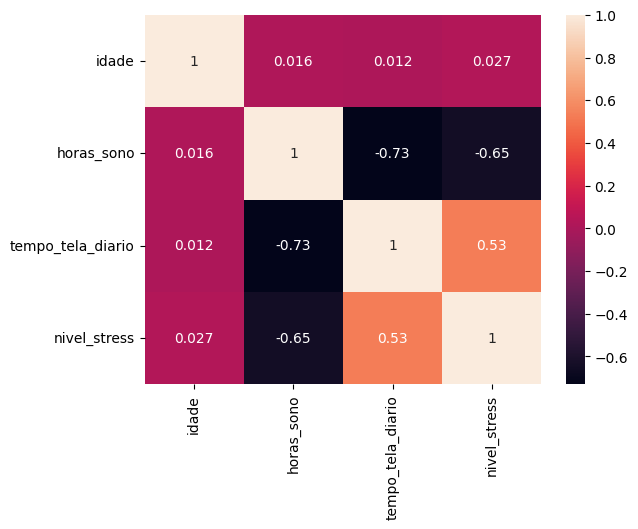

In [28]:
sns.heatmap(df_tratado.corr(numeric_only=True), annot=True)

In [29]:
fig = xp.scatter(df_tratado, x='nivel_stress', y='horas_sono', trendline='ols')
fig.update_traces(
    selector=dict(mode="lines"),
    line=dict(color="purple", width=3)
)

In [30]:
fig1 = xp.scatter(df_tratado.query('faixa_etaria == "15-25"'), x='nivel_stress', y='horas_sono', trendline='ols')
fig2 = xp.scatter(df_tratado.query('faixa_etaria == "25-35"'), x='nivel_stress', y='horas_sono', trendline='ols')
fig3 = xp.scatter(df_tratado.query('faixa_etaria == "35-45"'), x='nivel_stress', y='horas_sono', trendline='ols')
fig4 = xp.scatter(df_tratado.query('faixa_etaria == "45-55"'), x='nivel_stress', y='horas_sono', trendline='ols')


fig1.update_traces(
    selector=dict(mode="lines"),
    line=dict(color="purple", width=3)
)


fig2.update_traces(
    selector=dict(mode="lines"),
    line=dict(color="purple", width=3)
)

fig3.update_traces(
    selector=dict(mode="lines"),
    line=dict(color="purple", width=3)
)

fig4.update_traces(
    selector=dict(mode="lines"),
    line=dict(color="purple", width=3)
)

fig = mk(rows=2, cols=2, subplot_titles=('Faixa Etaria 15-25', 'Faixa Etaria 25-35', 'Faixa Etaria 35-45', 'Faixa Etaria 45-55'))

for t in fig1.data:
    fig.add_trace(t, row=1, col=1)

for t in fig2.data:
    fig.add_trace(t, row=2, col=1)

for t in fig3.data:
    fig.add_trace(t, row=1, col=2)

for t in fig4.data:
    fig.add_trace(t, row=2, col=2) 




fig.show()

aqui podemos notar uma correlação negativa entre o nivel de Strees e as horas de sono, logo a medida que o publico dorme mais o strees tende a diminuir apentemente o comportamento segue para todas as faixas de idade